# Course 11: Mathematics for Machine Learning
## Session 12: Graphs and matrices: from PageRank to graph neural networks

**Goal:** represent graphs as adjacency and Laplacian matrices, find stationary distributions of random walks, compute PageRank by power iteration, cluster two moons spectrally, and write one graph convolution as a matrix product and as message passing.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: a graph is a matrix
For a graph with $n$ nodes, the **adjacency matrix** $A$ has $A_{ij} = 1$ when there is an edge from $i$ to $j$; for an undirected graph it is symmetric. The **degree** $d_i = \sum_j A_{ij}$ counts the neighbours of node $i$, $D = \text{diag}(d)$, and the **graph Laplacian** is $L = D - A$. The entry $(A^k)_{ij}$ counts the walks of length $k$ from $i$ to $j$.

On paper, for the path 1 – 2 – 3: write $A$, $D$ and $L$, and check that $(1, 0, -1)$ is an eigenvector of $L$. What is its eigenvalue? For a triangle, what is the diagonal of $A^2$, and why does $\text{trace}(A^3)/6$ count the triangles?

In [1]:
import math, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import kneighbors_graph

t_start = time.time()
np.random.seed(0)

A_path = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]], dtype=float)
L_path = np.diag(A_path.sum(axis=1)) - A_path
print("path 1 - 2 - 3, Laplacian L = D - A:\n", L_path.astype(int))
print(f"L @ (1, 0, -1) = {L_path @ np.array([1.0, 0.0, -1.0])}, so the eigenvalue is 1")
print(f"all eigenvalues of L (np.linalg.eigh): {np.round(np.linalg.eigvalsh(L_path), 10) + 0.0}")
A_tri = np.ones((3, 3)) - np.eye(3)
print(f"triangle: diagonal of A^2 = {np.diag(A_tri @ A_tri)} (each node's degree); "
      f"trace(A^3) = {np.trace(np.linalg.matrix_power(A_tri, 3)):.0f}, divided by 6 = {np.trace(np.linalg.matrix_power(A_tri, 3)) / 6:.0f} triangle")

path 1 - 2 - 3, Laplacian L = D - A:
 [[ 1 -1  0]
 [-1  2 -1]
 [ 0 -1  1]]
L @ (1, 0, -1) = [ 1.  0. -1.], so the eigenvalue is 1
all eigenvalues of L (np.linalg.eigh): [0. 1. 3.]
triangle: diagonal of A^2 = [2. 2. 2.] (each node's degree); trace(A^3) = 6, divided by 6 = 1 triangle


### 2. Random walks and stationary distributions
A random walk moves from node $i$ to a random neighbour, so its transition matrix is $P = D^{-1}A$ (every row sums to 1). A distribution over nodes, written as a row vector $\pi_t$, evolves as $\pi_{t+1} = \pi_t P$. A **stationary distribution** satisfies $\pi = \pi P$: it is a left eigenvector of $P$ with eigenvalue 1, that is, an eigenvector of $P^\top$. For a connected undirected graph it is $\pi_i = d_i / \sum_j d_j$.

From any start, the walk converges to $\pi$ if the graph is connected and **not bipartite** (its nodes cannot be split into two groups with edges only between the groups). We compare a graph made of two triangles joined by an edge with a star (a centre and three leaves), which is bipartite, and with a **lazy** walk on the star that stays put with probability 1/2.

In [2]:
def stationary(P):                                             # left eigenvector of P for the eigenvalue closest to 1
    w, V = np.linalg.eig(P.T); v = np.real(V[:, np.argmin(np.abs(w - 1))]); return v / v.sum()
def walk(P, start, steps):
    pi = np.zeros(len(P)); pi[start] = 1.0; out = [pi]
    for _ in range(steps):
        pi = pi @ P; out.append(pi)
    return np.array(out)

A_two = np.zeros((6, 6))
for i, j in [(0, 1), (0, 2), (1, 2), (2, 3), (3, 4), (3, 5), (4, 5)]:
    A_two[i, j] = A_two[j, i] = 1
A_star = np.zeros((4, 4)); A_star[0, 1:] = A_star[1:, 0] = 1
tv_curves = {}
for name, A, lazy in [("two triangles", A_two, False), ("star (bipartite)", A_star, False), ("star, lazy walk", A_star, True)]:
    P = A / A.sum(axis=1, keepdims=True)
    if lazy: P = 0.5 * (np.eye(len(A)) + P)
    pi_deg = A.sum(axis=1) / A.sum()
    hist = walk(P, 0, 60)
    tv_curves[name] = 0.5 * np.abs(hist - pi_deg).sum(axis=1)  # total variation distance to the stationary distribution
    print(f"{name:17s}: degrees / sum = {np.round(pi_deg, 4)}; eigenvector of P^T = {np.round(stationary(P), 4)}; "
          f"walk from node 0 after 59 and 60 steps: {np.round(hist[59], 3)} {np.round(hist[60], 3)}")

two triangles    : degrees / sum = [0.1429 0.1429 0.2143 0.2143 0.1429 0.1429]; eigenvector of P^T = [0.1429 0.1429 0.2143 0.2143 0.1429 0.1429]; walk from node 0 after 59 and 60 steps: [0.143 0.143 0.214 0.214 0.143 0.143] [0.143 0.143 0.214 0.214 0.143 0.143]
star (bipartite) : degrees / sum = [0.5    0.1667 0.1667 0.1667]; eigenvector of P^T = [0.5    0.1667 0.1667 0.1667]; walk from node 0 after 59 and 60 steps: [0.    0.333 0.333 0.333] [1. 0. 0. 0.]
star, lazy walk  : degrees / sum = [0.5    0.1667 0.1667 0.1667]; eigenvector of P^T = [0.5    0.1667 0.1667 0.1667]; walk from node 0 after 59 and 60 steps: [0.5   0.167 0.167 0.167] [0.5   0.167 0.167 0.167]


### 3. PageRank by power iteration
PageRank (Page et al. 1999) imagines a surfer who, with probability $\alpha$ (the **damping factor**, usually 0.85), follows a random link from the current page, and otherwise jumps to a page chosen uniformly at random. A page with no out-links (a **dangling** page) jumps anywhere. The surfer's stationary distribution is the PageRank vector $r = rG$, with the Google matrix $G = \alpha P + (1 - \alpha)\frac{1}{n}\mathbf{1}\mathbf{1}^\top$.

**Power iteration** repeats $r \leftarrow rG$. Since $r_{t+1} - r = \alpha (r_t - r) P$ and multiplying by a row-stochastic $P$ never increases the sum of absolute values, the error shrinks at least by the factor $\alpha$ each step.

**By hand first:** three pages with links 1 → 2, 2 → 1 and 3 → 1, and $\alpha = 0.85$. Page 3 has no in-links, so it only gets its teleport share, $(1 - \alpha)/3 = 0.05$. Write $r_1 = 0.05 + 0.85(r_2 + r_3)$ and $r_2 = 0.05 + 0.85 r_1$ and solve them.

three pages: PageRank [0.4865 0.4635 0.05  ] after 168 iterations (page 3 gets (1 - 0.85)/3 = 0.05)
eight pages, alpha = 0.85: PageRank [0.1067 0.0742 0.1546 0.041  0.2548 0.2454 0.0288 0.0945] after 153 iterations; largest difference from the leading eigenvector of G^T 2.0e-13
pages from highest to lowest rank: [4, 5, 2, 0, 7, 1, 3, 6]
alpha = 0.50:   36 iterations; pages 4 and 5 hold 0.322 of the rank; rank [0.131 0.102 0.175 0.087 0.168 0.154 0.07  0.113]
alpha = 0.85:  153 iterations; pages 4 and 5 hold 0.500 of the rank; rank [0.107 0.074 0.155 0.041 0.255 0.245 0.029 0.095]
alpha = 0.99: 2000 iterations (stopped at the limit); pages 4 and 5 hold 0.916 of the rank; rank [0.019 0.013 0.027 0.005 0.459 0.457 0.003 0.017]
alpha = 1.00: 2000 iterations (stopped at the limit); pages 4 and 5 hold 1.000 of the rank; rank [0.    0.    0.    0.    0.486 0.514 0.    0.   ]


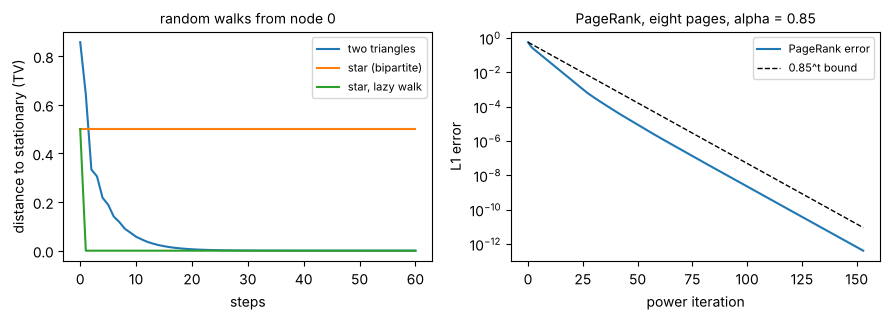

In [3]:
def google_matrix(links, n, alpha):
    P = np.zeros((n, n))
    for i, outs in links.items():
        for j in outs: P[i, j] = 1 / len(outs)
    P[P.sum(axis=1) == 0] = 1 / n                               # dangling pages jump anywhere
    return alpha * P + (1 - alpha) / n                          # every row of G sums to 1

def pagerank(G, tol=1e-12, max_iter=10000):
    r = np.full(len(G), 1 / len(G)); hist = [r]
    for t in range(max_iter):
        r_new = r @ G; hist.append(r_new)
        if np.abs(r_new - r).sum() < tol: break
        r = r_new
    return r_new, np.array(hist)

r3, h3 = pagerank(google_matrix({0: [1], 1: [0], 2: [0]}, 3, 0.85))
print(f"three pages: PageRank {np.round(r3, 4)} after {len(h3) - 1} iterations (page 3 gets (1 - 0.85)/3 = 0.05)")

links = {0: [1, 2], 1: [2], 2: [0, 7], 3: [2, 4], 4: [5], 5: [4], 6: [0, 3], 7: []}   # page 7 is dangling; 4 <-> 5 trap the surfer
n = 8
G = google_matrix(links, n, 0.85)
r, hist = pagerank(G)
v = stationary(G)
print(f"eight pages, alpha = 0.85: PageRank {np.round(r, 4)} after {len(hist) - 1} iterations; "
      f"largest difference from the leading eigenvector of G^T {np.abs(r - v).max():.1e}")
print("pages from highest to lowest rank:", np.argsort(-r).tolist())
err = np.abs(hist - v).sum(axis=1)                              # error against the eigenvector, computed separately
for alpha in [0.5, 0.85, 0.99, 1.0]:
    ra, ha = pagerank(google_matrix(links, n, alpha), max_iter=2000)
    print(f"alpha = {alpha:4.2f}: {len(ha) - 1:4d} iterations{' (stopped at the limit)' if len(ha) - 1 == 2000 else ''}; "
          f"pages 4 and 5 hold {ra[4] + ra[5]:.3f} of the rank; rank {np.round(ra, 3)}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for name, tv in tv_curves.items():
    ax[0].plot(tv, label=name)
ax[0].set_xlabel("steps"); ax[0].set_ylabel("distance to stationary (TV)"); ax[0].set_title("random walks from node 0", fontsize=10); ax[0].legend(fontsize=8)
ax[1].semilogy(err, label="PageRank error")
ax[1].semilogy(err[0] * 0.85 ** np.arange(len(err)), "k--", lw=1, label="0.85^t bound")
ax[1].set_xlabel("power iteration"); ax[1].set_ylabel("L1 error"); ax[1].set_title("PageRank, eight pages, alpha = 0.85", fontsize=10); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4. The Laplacian and spectral clustering
The Laplacian measures how much a signal $x$ on the nodes changes across edges: $x^\top L x = \sum_{\text{edges } (i,j)} (x_i - x_j)^2 \ge 0$. So $L$ is positive semidefinite, $L\mathbf{1} = 0$, and the number of zero eigenvalues equals the number of connected components (von Luxburg 2007). Eigenvectors with small eigenvalues vary slowly across edges, so they reveal clusters.

**Spectral clustering** (Ng, Jordan & Weiss 2001): build a similarity graph (here: connect each point to its 10 nearest neighbours, made symmetric), take the eigenvectors of the normalized Laplacian $L_{\text{sym}} = I - D^{-1/2} A D^{-1/2}$ for the 2 smallest eigenvalues, scale each row to length 1, and run k-means on the rows. We compare it with k-means on the raw coordinates of two moons, measuring agreement with the true moons by the adjusted Rand index (ARI: 1 for perfect agreement, about 0 for chance). We run it twice, on moons with noise 0.05 and 0.07, and count the graph's edges that join the two moons.

x^T L x = 2.496275; sum over edges of (x_i - x_j)^2 = 2.496275
eigenvalues of L: two triangles joined [0.     0.4384 3.     3.     3.     4.5616]; bridge removed [0. 0. 3. 3. 3. 3.]
noise 0.05: 1690 edges, 1 of them between the moons, 1 connected component(s); smallest eigenvalues of L_sym [0.     0.0006 0.0028 0.0035]
   adjusted Rand index: k-means on coordinates 0.241; our spectral clustering 1.000; scikit-learn SpectralClustering 1.000 (it warned that its own graph is not connected)
   normalized cut of the graph: true moons 0.0012, spectral partition 0.0012


noise 0.07: 1751 edges, 7 of them between the moons, 1 connected component(s); smallest eigenvalues of L_sym [0.     0.0016 0.0044 0.0055]
   adjusted Rand index: k-means on coordinates 0.234; our spectral clustering 0.650; scikit-learn SpectralClustering 0.639
   normalized cut of the graph: true moons 0.0080, spectral partition 0.0131


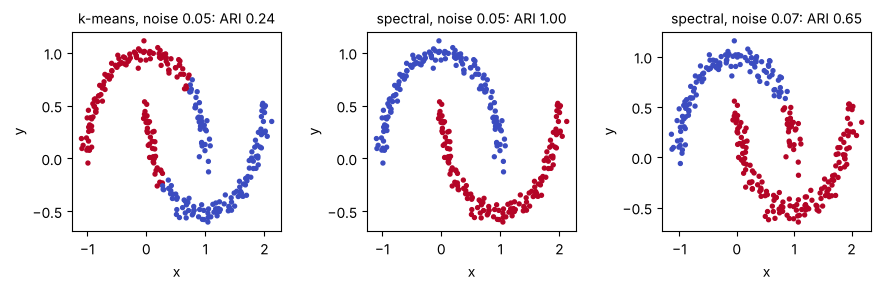

In [4]:
rng = np.random.default_rng(0)
x = rng.normal(size=6)
L_two = np.diag(A_two.sum(axis=1)) - A_two
edges = [(i, j) for i in range(6) for j in range(i + 1, 6) if A_two[i, j]]
print(f"x^T L x = {x @ L_two @ x:.6f}; sum over edges of (x_i - x_j)^2 = {sum((x[i] - x[j]) ** 2 for i, j in edges):.6f}")
A_split = A_two.copy(); A_split[2, 3] = A_split[3, 2] = 0         # remove the bridge: two separate triangles
print(f"eigenvalues of L: two triangles joined {np.round(np.linalg.eigvalsh(L_two), 4) + 0.0}; "
      f"bridge removed {np.round(np.linalg.eigvalsh(np.diag(A_split.sum(1)) - A_split), 4) + 0.0}")

def spectral(X, k=10):
    W = kneighbors_graph(X, n_neighbors=k, include_self=False).toarray()
    W = np.maximum(W, W.T)                                     # i ~ j if either is among the other's k nearest neighbours
    dinv = 1 / np.sqrt(W.sum(axis=1))
    L_sym = np.eye(len(W)) - dinv[:, None] * W * dinv[None, :]
    evals, evecs = np.linalg.eigh(L_sym)
    U = evecs[:, :2] / np.linalg.norm(evecs[:, :2], axis=1, keepdims=True)   # Ng, Jordan & Weiss: rows scaled to length 1
    return W, evals, KMeans(2, n_init=10, random_state=0).fit_predict(U)

def ncut(W, labels):                                           # normalized cut: cut/vol(A) + cut/vol(B)
    a = labels == labels[0]
    cut = W[np.ix_(a, ~a)].sum()
    return cut / W[a].sum() + cut / W[~a].sum()

moons = {}
for noise in [0.05, 0.07]:
    Xm, ym = make_moons(n_samples=300, noise=noise, random_state=0)
    W, evals, lab_spec = spectral(Xm)
    lab_km = KMeans(2, n_init=10, random_state=0).fit_predict(Xm)
    with warnings.catch_warnings(record=True) as caught:      # scikit-learn counts each point as one of its own 10 neighbours
        warnings.simplefilter("always")
        lab_skl = SpectralClustering(2, affinity="nearest_neighbors", n_neighbors=10, random_state=0).fit_predict(Xm)
    skl_note = " (it warned that its own graph is not connected)" if any("not fully connected" in str(w.message) for w in caught) else ""
    cross = int(W[np.ix_(ym == 0, ym == 1)].sum())
    moons[noise] = (Xm, lab_km, lab_spec, adjusted_rand_score(ym, lab_km), adjusted_rand_score(ym, lab_spec))
    print(f"noise {noise}: {int(W.sum() / 2)} edges, {cross} of them between the moons, {connected_components(W, directed=False)[0]} "
          f"connected component(s); smallest eigenvalues of L_sym {np.round(evals[:4], 4) + 0.0}")
    print(f"   adjusted Rand index: k-means on coordinates {moons[noise][3]:.3f}; our spectral clustering {moons[noise][4]:.3f}; "
          f"scikit-learn SpectralClustering {adjusted_rand_score(ym, lab_skl):.3f}{skl_note}")
    print(f"   normalized cut of the graph: true moons {ncut(W, ym):.4f}, spectral partition {ncut(W, lab_spec):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (noise, j, name) in zip(ax, [(0.05, 1, "k-means"), (0.05, 2, "spectral"), (0.07, 2, "spectral")]):
    Xm, labs, ari = moons[noise][0], moons[noise][j], moons[noise][j + 2]
    a.scatter(Xm[:, 0], Xm[:, 1], c=labs, s=8, cmap="coolwarm"); a.set_xlabel("x"); a.set_ylabel("y")
    a.set_title(f"{name}, noise {noise}: ARI {ari:.2f}", fontsize=10)
plt.tight_layout(); plt.show()

### 5. One graph convolution: a matrix product and message passing
A graph convolutional network (GCN) layer (Kipf & Welling 2017) computes $H' = \text{ReLU}(\hat A H W)$, where $\hat A = \tilde D^{-1/2}(A + I)\tilde D^{-1/2}$ adds self-loops and normalizes by the degrees $\tilde d_i = d_i + 1$, and $W$ is a weight matrix shared by all nodes. Row $i$ of $\hat A H$ is a weighted sum over node $i$ and its neighbours, $\sum_j h_j/\sqrt{\tilde d_i \tilde d_j}$: message passing.

**By hand first:** for the path 1 – 2 – 3 with self-loops, $\tilde d = (2, 3, 2)$. What weights does node 2 give to nodes 1, 2 and 3? Do the rows of $\hat A$ sum to 1?

Then we compute one layer on a graph of two groups of four nodes joined by one edge, as a matrix product and as an explicit loop over nodes and neighbours.

In [5]:
def gcn_normalize(A):
    At = A + np.eye(len(A)); dt = At.sum(axis=1)
    return At / np.sqrt(dt)[:, None] / np.sqrt(dt)[None, :]

Ah = gcn_normalize(A_path)
print("A_hat for the path 1 - 2 - 3:\n", np.round(Ah, 4), "\nrow sums:", np.round(Ah.sum(axis=1), 4))

A8 = np.zeros((8, 8))
for grp in [range(0, 4), range(4, 8)]:
    for i in grp:
        for j in grp:
            if i != j: A8[i, j] = 1
A8[3, 4] = A8[4, 3] = 1                                         # the single edge between the groups
rng = np.random.default_rng(1)
X8, W8 = rng.normal(size=(8, 3)), rng.normal(size=(3, 2))
Ah8 = gcn_normalize(A8)
H_matrix = np.maximum(Ah8 @ X8 @ W8, 0)
dt = A8.sum(axis=1) + 1
H_loop = np.zeros((8, 2))
for i in range(8):                                              # message passing, written out
    msg = sum(X8[j] @ W8 / np.sqrt(dt[i] * dt[j]) for j in range(8) if A8[i, j] or i == j)
    H_loop[i] = np.maximum(msg, 0)
print(f"one GCN layer on 8 nodes: largest difference between matrix form and loop {np.abs(H_matrix - H_loop).max():.1e}")
ev, evec = np.linalg.eigh(Ah8)
top = evec[:, -1] * np.sign(evec[:, -1].sum())
print(f"eigenvalues of A_hat from {ev.min():.4f} to {ev.max():.4f}; top eigenvector / sqrt(d + 1) = {np.round(top / np.sqrt(dt), 4)}")

A_hat for the path 1 - 2 - 3:
 [[0.5    0.4082 0.    ]
 [0.4082 0.3333 0.4082]
 [0.     0.4082 0.5   ]] 
row sums: [0.9082 1.1498 0.9082]
one GCN layer on 8 nodes: largest difference between matrix form and loop 2.2e-16


eigenvalues of A_hat from -0.1641 to 1.0000; top eigenvector / sqrt(d + 1) = [0.1715 0.1715 0.1715 0.1715 0.1715 0.1715 0.1715 0.1715]


### 6. What repeated propagation does: smoothing, then oversmoothing
Stacking $k$ propagation steps applies $\hat A^k$. Each step averages a node with its neighbours, which removes noise; but $\hat A^k x$ approaches the top eigenvector, proportional to $\sqrt{\tilde d_i}$, whatever $x$ was, so after many steps every node looks alike (Course 6 session 4 calls this **oversmoothing**).

We generate a graph with two groups of 50 nodes (edge probability 0.15 inside a group, 0.02 between groups) and give each node one noisy feature: +1 or −1 for its group, plus Gaussian noise with standard deviation 1. We guess each node's group from the sign of its feature after $k$ steps.

graph: 412 edges; second-largest eigenvalue of A_hat 0.8436
k =   0 steps: accuracy from the sign 0.84; cosine with sqrt(degree + 1) 0.0346
k =   1 steps: accuracy from the sign 0.97; cosine with sqrt(degree + 1) 0.0556
k =   2 steps: accuracy from the sign 0.99; cosine with sqrt(degree + 1) 0.0694
k =   4 steps: accuracy from the sign 0.99; cosine with sqrt(degree + 1) 0.0994
k =   8 steps: accuracy from the sign 0.98; cosine with sqrt(degree + 1) 0.1945
k =  16 steps: accuracy from the sign 0.89; cosine with sqrt(degree + 1) 0.6118
k =  32 steps: accuracy from the sign 0.50; cosine with sqrt(degree + 1) 0.9964
k =  64 steps: accuracy from the sign 0.50; cosine with sqrt(degree + 1) 1.0000
k = 128 steps: accuracy from the sign 0.50; cosine with sqrt(degree + 1) 1.0000
k = 256 steps: accuracy from the sign 0.50; cosine with sqrt(degree + 1) 1.0000


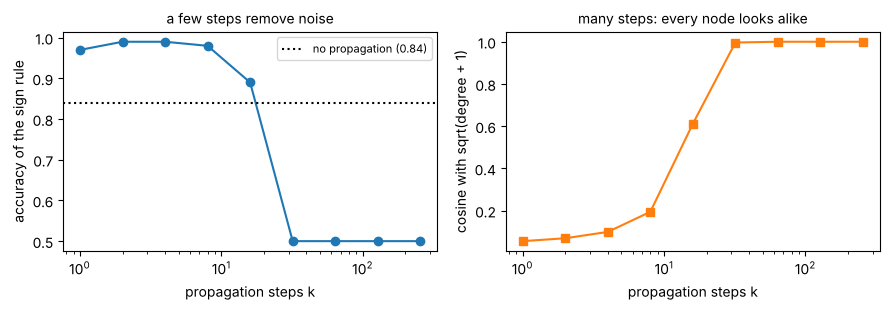

runtime so far 1 s


In [6]:
rng = np.random.default_rng(2)
groups = np.repeat([0, 1], 50)
prob = np.where(groups[:, None] == groups[None, :], 0.15, 0.02)
upper = np.triu(rng.random((100, 100)) < prob, 1)
A_sbm = (upper | upper.T).astype(float)
truth = np.where(groups == 0, 1.0, -1.0)
x0 = truth + rng.normal(0, 1.0, 100)
Ah_sbm = gcn_normalize(A_sbm)
sq = np.sqrt(A_sbm.sum(axis=1) + 1)
ks = [0, 1, 2, 4, 8, 16, 32, 64, 128, 256]
acc, cos = [], []
print(f"graph: {int(A_sbm.sum() / 2)} edges; second-largest eigenvalue of A_hat {np.sort(np.linalg.eigvalsh(Ah_sbm))[-2]:.4f}")
for k in ks:
    xk = np.linalg.matrix_power(Ah_sbm, k) @ x0
    acc.append(max(np.mean(np.sign(xk) == truth), np.mean(np.sign(xk) == -truth)))   # the sign of a group label is arbitrary
    cos.append(abs(xk @ sq) / (np.linalg.norm(xk) * np.linalg.norm(sq)))
    print(f"k = {k:3d} steps: accuracy from the sign {acc[-1]:.2f}; cosine with sqrt(degree + 1) {cos[-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].semilogx(np.array(ks[1:]), acc[1:], "o-"); ax[0].axhline(acc[0], color="k", ls=":", label=f"no propagation ({acc[0]:.2f})")
ax[0].set_xlabel("propagation steps k"); ax[0].set_ylabel("accuracy of the sign rule"); ax[0].set_title("a few steps remove noise", fontsize=10); ax[0].legend(fontsize=8)
ax[1].semilogx(np.array(ks[1:]), cos[1:], "s-", color="C1")
ax[1].set_xlabel("propagation steps k"); ax[1].set_ylabel("cosine with sqrt(degree + 1)"); ax[1].set_title("many steps: every node looks alike", fontsize=10)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 7. A trained GCN on a real citation graph (NOT RUN here)
Course 6 session 2 trains a two-layer GCN on Cora (2,708 papers, 7 topics, 140 labelled papers). Each `GCNConv` layer is exactly section 5's $\hat A H W$, with sparse matrices. It needs PyTorch Geometric and a download.

In [ ]:
# NOT RUN: needs torch_geometric and a download of the Cora citation graph (a few MB)
import torch, torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv
data = Planetoid(root="data/Cora", name="Cora")[0]
class GCN(torch.nn.Module):
    def __init__(self, d_in, d_hidden, d_out):
        super().__init__(); self.conv1, self.conv2 = GCNConv(d_in, d_hidden), GCNConv(d_hidden, d_out)
    def forward(self, x, edge_index):
        x = F.dropout(x, p=0.5, training=self.training)
        x = F.relu(self.conv1(x, edge_index))                   # one layer: A_hat X W, then ReLU
        x = F.dropout(x, p=0.5, training=self.training)
        return self.conv2(x, edge_index)
torch.manual_seed(0)
model = GCN(data.num_features, 16, int(data.y.max()) + 1)
opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
for epoch in range(200):
    model.train(); opt.zero_grad()
    loss = F.cross_entropy(model(data.x, data.edge_index)[data.train_mask], data.y[data.train_mask])
    loss.backward(); opt.step()
model.eval(); pred = model(data.x, data.edge_index).argmax(dim=1)
print(f"Cora test accuracy {(pred[data.test_mask] == data.y[data.test_mask]).float().mean():.3f} (Kipf & Welling report 81.5%)")

### 8. Exercises

In [7]:
# TODO: personalized PageRank. Replace the uniform jump (1 - alpha)/n by a jump that always returns to page 0, so that
# G = alpha * P + (1 - alpha) * 1 e_0^T (every row's jump goes to page 0). Compute it for the eight pages with
# alpha = 0.85 and return the vector. Which pages are "close to" page 0? Personalized PageRank is used to rank
# nodes by their relevance to one node, for example in recommendation.
def personalized_pagerank():
    return None          # replace with your code

r = personalized_pagerank()
print("not done yet" if r is None else np.round(r, 4))

not done yet


In [8]:
# TODO: random-walk normalization. Repeat section 6 with A_rw = D_tilde^{-1} (A + I) instead of A_hat. Check that every
# row of A_rw sums to 1, find the vector that A_rw^k x approaches for large k (hint: the right eigenvector of A_rw for
# eigenvalue 1), and return the accuracies for the same values of k. Does oversmoothing still happen?
def random_walk_smoothing():
    return None          # replace with your code

r = random_walk_smoothing()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **Matrices count walks and measure change.** For the path 1 – 2 – 3, $L(1, 0, -1)^\top = (1, 0, -1)^\top$, so the eigenvalue is 1, and the eigenvalues of $L$ are 0, 1 and 3. For the triangle, the diagonal of $A^2$ holds the degrees (2, 2, 2), and $\text{trace}(A^3)/6 = 1$ triangle.
2. **A random walk settles at $d_i/\sum_j d_j$, unless the graph is bipartite.** On the two triangles the walk from node 0 reached (0.143, 0.143, 0.214, 0.214, 0.143, 0.143), the degrees divided by 14, and the eigenvector of $P^\top$ agreed. On the star it alternated for ever between the centre, (1, 0, 0, 0), and the leaves, (0, 1/3, 1/3, 1/3), staying 0.5 away from (1/2, 1/6, 1/6, 1/6) in total variation; the lazy walk reached the stationary distribution in one step.
3. **PageRank, by hand and by power iteration.** The three pages gave (0.4865, 0.4635, 0.05), as solved by hand. For the eight pages, power iteration converged in 153 iterations, agreed with the leading eigenvector of $G^\top$ to 2.0e-13, and its error stayed under the $0.85^t$ bound. Pages 4 and 5, which link only to each other, ranked highest (0.2548 and 0.2454).
4. **The damping factor is a trade-off.** With $\alpha$ = 0.5, power iteration needed 36 iterations and pages 4 and 5 held 0.322 of the rank; with 0.85, 153 iterations and 0.500; with 0.99, more than 2,000 iterations (the run stopped at its limit) and 0.916. With no damping ($\alpha$ = 1) the trap took all of the rank, and the iteration never settled, because the surfer alternates between pages 4 and 5 (0.486 and 0.514 when it stopped).
5. **The Laplacian counts connected components.** $x^\top L x$ equalled the sum of $(x_i - x_j)^2$ over the edges (2.496275). Removing the bridge between the two triangles turned the second eigenvalue from 0.4384 into a second 0.
6. **Spectral clustering solves a relaxed problem, and it can miss.** At noise 0.05, only 1 of the k-nearest-neighbour graph's 1,690 edges joined the moons, and spectral clustering was perfect (ARI 1.000) where k-means scored 0.241. At noise 0.07, with 7 of 1,751 edges between the moons, it scored only 0.650 (scikit-learn: 0.639), cutting across both moons. **Against expectation,** the true moons still had the smaller normalized cut (0.0080 against 0.0131 for the spectral partition): the eigenvectors solve a continuous relaxation of the cut problem, and their answer can be worse than the best cut (von Luxburg 2007). scikit-learn's own graph, which counts each point as one of its 10 neighbours, had no edge between the moons at noise 0.05; it warned that the graph was not connected.
7. **One GCN layer is two matrix products.** For the path with self-loops, node 2 weighs nodes 1, 2 and 3 by 0.4082, 0.3333 and 0.4082, and the rows of $\hat A$ sum to 0.9082, 1.1498 and 0.9082, not 1. On the 8-node graph the matrix form and the explicit message-passing loop agreed to 2.2e-16, and the eigenvalues of $\hat A$ lay between −0.1641 and 1.0000, with the top eigenvector proportional to $\sqrt{d_i + 1}$.
8. **A few propagation steps help; many erase the signal.** Guessing the group from the sign of the noisy feature gave 0.84 accuracy with no propagation, 0.97 to 0.99 after 1 to 8 steps, 0.89 after 16, and 0.50 (chance) from 32 steps on, when every feature vector had become proportional to $\sqrt{d_i + 1}$ (cosine 0.9964 at 32 steps, 1.0000 after). The second-largest eigenvalue of $\hat A$, 0.8436, sets how fast the group signal fades.